SANTIAGO DIE MOREJÓN - 21/04/2026 - IA - Entregable 2 Adicional 3 - LR finder

# Notebook 4: LR finder(Learning Rate Finder)
En este notebook aplicamos la técnica Learning Rate Finder para seleccionar un *learning rate* óptimo antes de entrenar el modelo.

## 0. Instalación y carga de librerías

In [1]:
!pip install fastai timm -Uq

In [2]:
from fastai.vision.all import *
import timm
import os
import shutil
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## 1. Carga y preparación del dataset

Usamos el mismo dataset de imágenes satelitales del notebook principal.

In [3]:
!wget DATA_URL -O archive.zip
!unzip -q archive.zip

--2026-04-27 22:18:05--  DATA_URL
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22836290 (22M) [application/zip]
Saving to: ‘archive.zip’

archive.zip         100%[===================>]  21.78M   135MB/s    in 0.2s    

2026-04-27 22:18:06 (135 MB/s) - ‘archive.zip’ saved [22836290/22836290]



In [4]:
os.makedirs('/content/data/satellite/train', exist_ok=True)
os.makedirs('/content/data/satellite/test', exist_ok=True)

for c in ['cloudy', 'desert', 'green_area', 'water']:
    os.makedirs(f'/content/data/satellite/train/{c}', exist_ok=True)
    os.makedirs(f'/content/data/satellite/test/{c}', exist_ok=True)

In [5]:
path = Path('/content/data')

In [6]:
for im in verify_images(get_image_files('/content/data')):
    os.remove(str(im))

In [7]:
from sklearn.model_selection import train_test_split

trainCloudy,   testCloudy   = train_test_split(get_image_files(path/'cloudy'),    test_size=0.2, random_state=15)
trainDesert,   testDesert   = train_test_split(get_image_files(path/'desert'),    test_size=0.2, random_state=15)
trainGreen,    testGreen    = train_test_split(get_image_files(path/'green_area'),test_size=0.2, random_state=15)
trainWater,    testWater    = train_test_split(get_image_files(path/'water'),     test_size=0.2, random_state=15)

In [8]:
for x in trainCloudy:
    shutil.move(str(x), path/('satellite/train/cloudy/'+x.name))

for x in trainDesert:
    shutil.move(str(x), path/('satellite/train/desert/'+x.name))

for x in trainGreen:
    shutil.move(str(x), path/('satellite/train/green_area/'+x.name))

for x in trainWater:
    shutil.move(str(x), path/('satellite/train/water/'+x.name))


In [9]:
for x in testCloudy:
    shutil.move(str(x), path/('satellite/test/cloudy/'+x.name))

for x in testDesert:
    shutil.move(str(x), path/('satellite/test/desert/'+x.name))

for x in testGreen:
    shutil.move(str(x), path/('satellite/test/green_area/'+x.name))

for x in testWater:
    shutil.move(str(x), path/('satellite/test/water/'+x.name))

In [10]:
shutil.rmtree(path/'cloudy')
shutil.rmtree(path/'desert')
shutil.rmtree(path/'green_area')
shutil.rmtree(path/'water')

## 2. Creacion y ejecucion del learner

In [12]:
dls = ImageDataLoaders.from_folder(path/'satellite'/'train',
    valid_pct=0.2,
    seed=42,
    item_tfms=Resize(224),
    batch_tfms=aug_transforms(size=224, min_scale=0.75),
    bs=32
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 71.3MB/s]


<div></div>

SuggestedLRs(valley=0.002511886414140463)


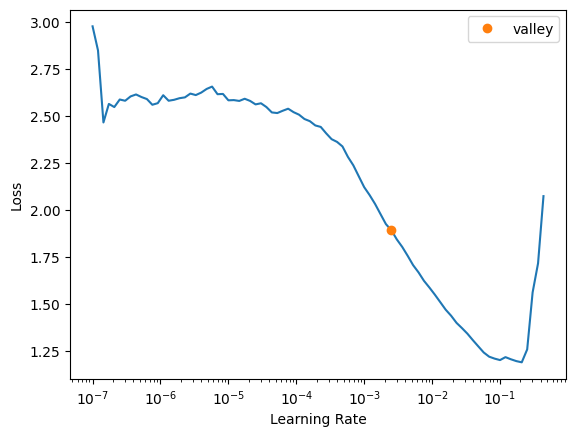

In [13]:
learn = vision_learner(dls, resnet18, metrics=[accuracy, error_rate])
lr_finder_results = learn.lr_find()
print(lr_finder_results)

## 3. Selección del LR

A partir de la gráfica elegimos el LR del valley como LR óptimo ya que es el recomendado por fastai para fine_tune.

In [15]:
LR_VALLEY  = lr_finder_results.valley
LR_DEFAULT = 1e-3
LR_HIGH    = 1e-2
print(f"LR valley:  {LR_VALLEY:.2e}")
print(f"LR default: {LR_DEFAULT:.2e}")
print(f"LR alto:    {LR_HIGH:.2e}")

LR valley:  2.51e-03
LR default: 1.00e-03
LR alto:    1.00e-02


In [18]:
learn_valley = vision_learner(dls, resnet18, metrics=[accuracy, error_rate])
t0 = time.time()
learn_valley.fine_tune(5, base_lr=LR_VALLEY)
print(f"Valley (LR={LR_VALLEY:.2e}): {round(time.time()-t0, 1)}s")

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.281016,0.042463,0.983333,0.016667,00:25


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.101526,0.014022,0.996667,0.003333,00:19
1,0.079138,0.002846,0.997778,0.002222,00:20
2,0.042234,0.002019,1.000000,0.000000,00:19
3,0.031043,0.004753,0.997778,0.002222,00:20
4,0.019018,0.001550,1.000000,0.000000,00:20


Valley (LR=2.51e-03): 125.2s


In [19]:
learn_default = vision_learner(dls, resnet18, metrics=[accuracy, error_rate])
t0 = time.time()
learn_default.fine_tune(5, base_lr=LR_DEFAULT)
print(f"Default (LR={LR_DEFAULT:.2e}): {round(time.time()-t0, 1)}s")

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.502164,0.059487,0.982222,0.017778,00:16


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.103680,0.019051,0.993333,0.006667,00:20
1,0.095358,0.012636,0.994444,0.005556,00:19
2,0.057629,0.007375,0.996667,0.003333,00:20
3,0.035865,0.004065,0.998889,0.001111,00:19
4,0.035296,0.003749,0.998889,0.001111,00:20


Default (LR=1.00e-03): 115.8s


In [20]:
learn_high = vision_learner(dls, resnet18, metrics=[accuracy, error_rate])
t0 = time.time()
learn_high.fine_tune(5, base_lr=LR_HIGH)
print(f"Alto (LR={LR_HIGH:.2e}): {round(time.time()-t0, 1)}s")

epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.245424,0.021367,0.992222,0.007778,00:17


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,0.108637,0.012027,0.995556,0.004444,00:21
1,0.113831,0.006424,0.998889,0.001111,00:19
2,0.071006,0.006423,0.996667,0.003333,00:21
3,0.032653,0.001549,1.000000,0.000000,00:20
4,0.015388,0.002029,1.000000,0.000000,00:21


Alto (LR=1.00e-02): 121.9s


## 4. Analisis de los resultados

In [21]:
resultados_lr = {
    'Nombre': ['Valley', 'Default', 'Alto'],
    'LR': ['2.51e-03', '1.00e-03', '1.00e-02'],
    'Accuracy': [1.0000, 0.9989, 1.0000],
    'Error Rate': [0.0000, 0.0011, 0.0000],
    'Val Loss': [0.0015, 0.0037, 0.0020],
    'Tiempo (s)': [125.2,  115.8,  121.9],
}
df_lr = pd.DataFrame(resultados_lr)
print(df_lr.to_string(index=False))

 Nombre       LR  Accuracy  Error Rate  Val Loss  Tiempo (s)
 Valley 2.51e-03    1.0000      0.0000    0.0015       125.2
Default 1.00e-03    0.9989      0.0011    0.0037       115.8
   Alto 1.00e-02    1.0000      0.0000    0.0020       121.9


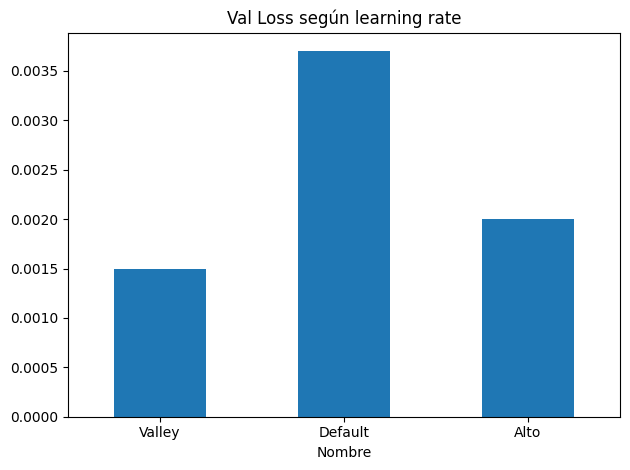

In [23]:
df_lr.plot.bar(x='Nombre', y='Val Loss', legend=False)
plt.title('Val Loss según learning rate')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Conclusiones

Los tres LRs alcanzan resultados muy similares en accuracy, pero la val_loss
revela diferencias claras: Valley (0.0015) < Alto (0.0020) < Default (0.0037).

El LR por defecto de fastai (1e-3) es el que peor val_loss obtiene a pesar de
ser el más conservador, lo que demuestra que un LR demasiado bajo no garantiza
mejor convergencia en el mismo número de épocas.

Contra lo esperado, el LR alto (1e-2) no causa inestabilidad y supera al
default, aunque no llega al nivel de Valley. Esto se debe a que el dataset
es suficientemente sencillo como para tolerar LRs agresivos.

El LR Finder cumple su objetivo ya que el valor sugerido obtiene la menor pérdida
de validación de los tres, confirmando que la selección sistemática del LR
es preferible al valor por defecto, aunque en datasets sencillos las
diferencias en accuracy sean pequeñas.